# 03 — Geospatial & Visual Analytics

**Objective:** Visualize behavioral churn drivers with `Seaborn`/`Matplotlib`, export high-resolution charts to `assets/` for documentation, and build an interactive `Folium` map of regional churn hotspots across Malaysia.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

sns.set_theme(style="whitegrid", palette="muted")
PROJECT_ROOT = Path("..").resolve()
DB_PATH = PROJECT_ROOT / "data" / "insurai.db"
ASSETS_DIR = PROJECT_ROOT / "assets"
ASSETS_DIR.mkdir(parents=True, exist_ok=True)

with sqlite3.connect(DB_PATH) as conn:
    df = pd.read_sql_query("SELECT * FROM policyholders;", conn)

print(f"Loaded {len(df)} records from {DB_PATH}")

Loaded 1500 records from C:\Users\danis\OneDrive\Desktop\Project\InsurAI Policyholder Retention & Risk Analytics Pipeline\data\insurai.db


## 1. Churn Rate by Policy Type & Annual Premium Distribution

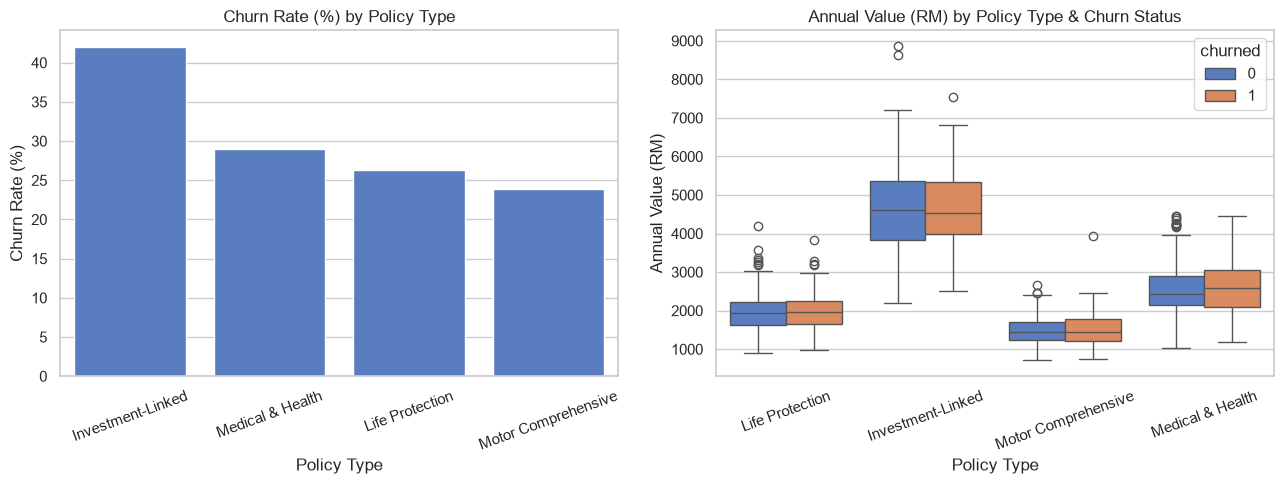

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

policy_churn = (
    df.groupby("policy_type", as_index=False)["churned"]
    .mean()
    .assign(churn_rate_pct=lambda x: x["churned"] * 100)
    .sort_values("churn_rate_pct", ascending=False)
)
sns.barplot(data=policy_churn, x="policy_type", y="churn_rate_pct", ax=axes[0])
axes[0].set_title("Churn Rate (%) by Policy Type")
axes[0].set_xlabel("Policy Type")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=df, x="policy_type", y="annual_value_rm", hue="churned", ax=axes[1])
axes[1].set_title("Annual Value (RM) by Policy Type & Churn Status")
axes[1].set_xlabel("Policy Type")
axes[1].set_ylabel("Annual Value (RM)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(ASSETS_DIR / "churn_by_policy_type.png", dpi=150)
plt.show()

## 2. Behavioral Risk Drivers: Late Payments & Support Tickets

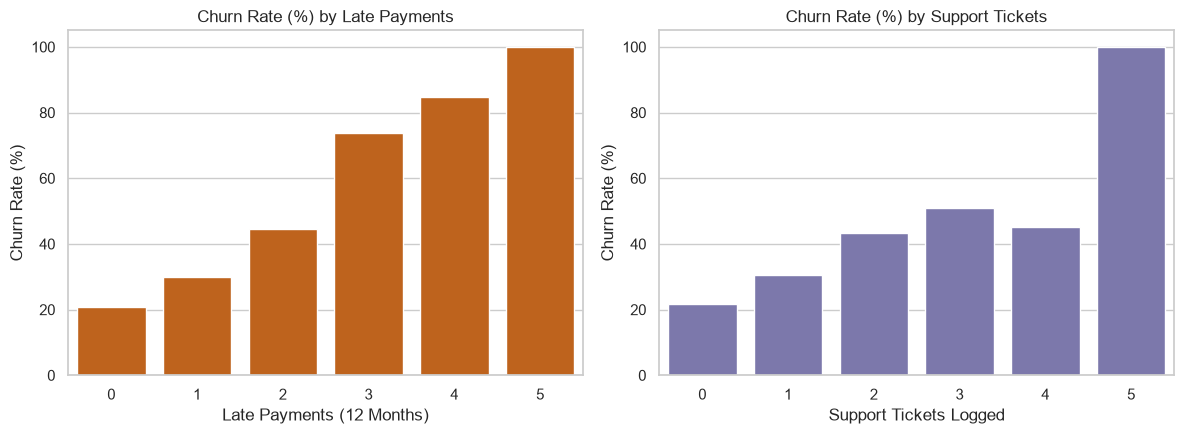

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

late_df = df.groupby("late_payments", as_index=False)["churned"].mean()
late_df["churn_rate_pct"] = late_df["churned"] * 100
sns.barplot(data=late_df, x="late_payments", y="churn_rate_pct", ax=axes[0], color="#d95f02")
axes[0].set_title("Churn Rate (%) by Late Payments")
axes[0].set_xlabel("Late Payments (12 Months)")
axes[0].set_ylabel("Churn Rate (%)")

ticket_df = df.groupby("support_tickets", as_index=False)["churned"].mean()
ticket_df["churn_rate_pct"] = ticket_df["churned"] * 100
sns.barplot(data=ticket_df, x="support_tickets", y="churn_rate_pct", ax=axes[1], color="#7570b3")
axes[1].set_title("Churn Rate (%) by Support Tickets")
axes[1].set_xlabel("Support Tickets Logged")
axes[1].set_ylabel("Churn Rate (%)")

plt.tight_layout()
plt.savefig(ASSETS_DIR / "churn_behavioral_drivers.png", dpi=150)
plt.show()

## 3. Numerical Feature Correlation Heatmap

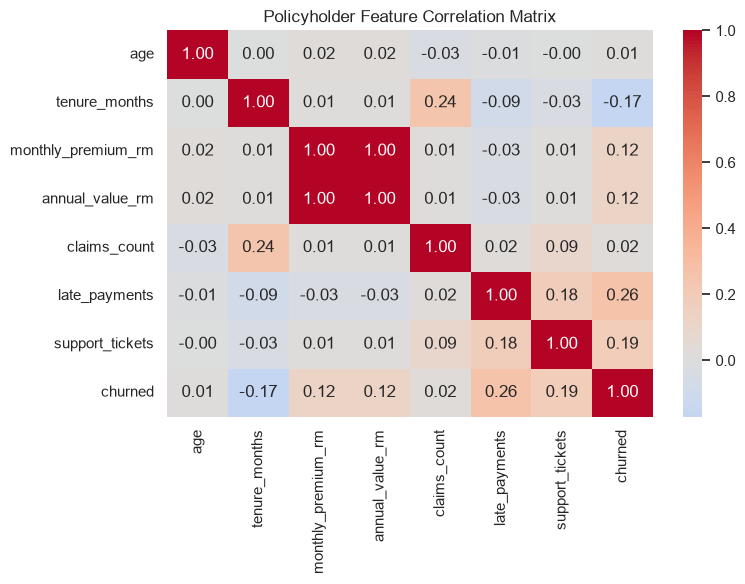

In [4]:
numeric_cols = [
    "age",
    "tenure_months",
    "monthly_premium_rm",
    "annual_value_rm",
    "claims_count",
    "late_payments",
    "support_tickets",
    "churned",
]
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Policyholder Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(ASSETS_DIR / "correlation_heatmap.png", dpi=150)
plt.show()

## 4. Geospatial Risk Map Across Malaysia (`Folium`)

In [5]:
REGION_COORDS = {
    "Kuala Lumpur": (3.1390, 101.6869),
    "Selangor": (3.0738, 101.5183),
    "Johor": (1.4927, 103.7414),
    "Penang": (5.4164, 100.3327),
    "Sarawak": (1.5533, 110.3592),
}

regional_summary = (
    df.groupby("region", as_index=False)
    .agg(
        total_policies=("policy_id", "count"),
        churned_policies=("churned", "sum"),
        churn_rate_pct=("churned", lambda s: round(s.mean() * 100, 2)),
        revenue_at_risk_rm=(
            "annual_value_rm",
            lambda s: round(s[df.loc[s.index, "churned"] == 1].sum(), 2),
        ),
    )
)
display(regional_summary)

m = folium.Map(location=[3.5, 105.0], zoom_start=6, tiles="CartoDB positron")

for _, row in regional_summary.iterrows():
    lat, lon = REGION_COORDS[row["region"]]
    color = "red" if row["churn_rate_pct"] >= 30 else "orange" if row["churn_rate_pct"] >= 25 else "green"
    popup_html = (
        f"<b>{row['region']}</b><br>"
        f"Policies: {row['total_policies']}<br>"
        f"Churned: {row['churned_policies']} ({row['churn_rate_pct']}%)<br>"
        f"Revenue at Risk: RM {row['revenue_at_risk_rm']:,.2f}"
    )
    folium.CircleMarker(
        location=[lat, lon],
        radius=max(10, row["churn_rate_pct"] * 0.7),
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.65,
        popup=folium.Popup(popup_html, max_width=250),
    ).add_to(m)

map_path = ASSETS_DIR / "malaysia_churn_risk_map.html"
m.save(str(map_path))
print(f"Saved interactive Folium map to: {map_path}")
m

,region,total_policies,churned_policies,churn_rate_pct,revenue_at_risk_rm
0,Johor,242,79,32.64,224255.40
1,Kuala Lumpur,437,148,33.87,404792.88
2,Penang,202,45,22.28,100945.44
3,Sarawak,180,39,21.67,96807.96
4,Selangor,439,120,27.33,314124.12


Saved interactive Folium map to: C:\Users\danis\OneDrive\Desktop\Project\InsurAI Policyholder Retention & Risk Analytics Pipeline\assets\malaysia_churn_risk_map.html


C:\Users\danis\OneDrive\Desktop\Project\InsurAI Policyholder Retention & Risk Analytics Pipeline\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore
